# Engineering features

## 0. Imports & Config

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
import ipaddress
import urllib.parse
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from scipy.stats import randint

TEST_SIZE = 0.2
RANDOM_STATE = 42

ARTIFACT_PATH = r"C:\Users\User\Documents\Key Future Docs\Projects\Phising URL\artifacts\artifact.joblib"

DATASET_PATH = r"C:\Users\User\Documents\Key Future Docs\Projects\Phising URL\dataset\new_data_urls.csv"
WORDS_TO_FLAG = ['free', 'account', 'verify', 'confirm', 'reset', 'update', 'change', 'login', 'signup', 'log-in', 'sign-up', 'bank', 'security', 'pay', 'payment', 'invoice', 'order', 'download', 'sign', 'click', 'here', 'link']

## 1. Loading the Dataset

In [2]:
df = pd.read_csv(DATASET_PATH)

df.reset_index(drop=True, inplace=True)
df.rename(columns={"status": "is_phishing"}, inplace=True)
df['is_phishing'] = df['is_phishing'] == 0

print("Total number of URLs in the dataset: ", len(df))
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Total number of URLs in the dataset:  822010


,url,is_phishing
3,mahalo.com/fringe/,False
8,facebook.com/canadianprincessresort,False
9,scholar.lib.vt.edu/theses/available/etd-051799...,False
0,stripe-processing.aba.cx,True
1,seeme.ddns.net,True
2,nambo.blob.core.windows.net,True
4,blackshots.net84.net/,True
5,iconigram.com/87hcnrewe,True
6,aquatixbottle.com/nyx37ec?iCTJWjXTh=XPrgCJrEBa,True
7,glosalonline.com/adsry1c,True


In [3]:
def is_ip(string):
    try:
        string = string.strip('[]')
        ipaddress.ip_address(string)
        return True
    except:
        return False

result = []
for i, row in df.iterrows():
    raw_url = row['url']
    is_ip_result = is_ip(raw_url)
    if '://' not in raw_url and not is_ip_result:
        raw_url = 'http://' + raw_url
    try:
        parsed_url = urllib.parse.urlparse(raw_url)
    except:
        print(f"Error parsing URL: {raw_url}")
        result.append([None, None, None, None, None, False])
        continue
    protocol = parsed_url.scheme
    domain = parsed_url.netloc
    subdomains = parsed_url.netloc.split('.')[:-1]
    path = parsed_url.path
    tld = parsed_url.netloc.split('.')[-1]
    result.append([protocol, domain, subdomains, path, tld, is_ip_result])

df = pd.concat([df, pd.DataFrame(result, columns=['protocol', 'domain', 'subdomains', 'path', 'tld', 'is_ip'])], axis=1)
df.dropna(inplace=True)
print(df["is_ip"].value_counts())
print(df.loc[df["is_ip"], "url"].head(10))
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Error parsing URL: http://RybjUxÙãl5»7ÆE%ÝÔk+h|U+ýk©ìÉ½Æq]âF·õÁ¢w)ëA·ç°{t*m!¦2
Error parsing URL: http://ÆeF§÷%¶¿Õ½9¿b@Ö¸ÚZE¤ÒC¢ÄÅª2åç-]W³fU¤Jgkz.ø¿nJçåæuøD%@ðûÇùM¹uË
Error parsing URL: http://Ó6¸RTÃu~æÙg0>÷mÖiÓ=;XZ\%êýÜÉfn&\°%7õÉ"ieÖ1ÄÁêFÐò<$cï6t[0ò2"/Æa^2âpù/ýãÇ$E¬R«È²ú[Ì¶p¥qÒ°i°^ò[»³»]±9êdÓS¿Ë]ùþ5j¿·ªocÂplà7ÊÏJ§¢#3ðDCDõ²çÇGÝ.Vò=¿QB§Ä'`ÊáZÉê ÔîÆm®ÍÝQÓ(z;¹Áê¬âytÖÙ®ëNP²ÜEQ
Error parsing URL: http://oÍÑOwEuÊÚÃß=nËß[j{2%.tñø­½½qx½NºPmx$Aì&ÝIhÂéc¶A9®cì3ßyiÚý~JÍf]$ö M¸°;xÃu0IÅ@xõe^cÃ ¸´ÞO7B~FrØ\<kÅb{T!Ìé	r?kX-YÇS@T)LeaÃ}°¡ùï4ºkïá2¢kEì¬ôfsçË×ÛQìê{o£UÜ§D©l½±±äâqôó¼-â0èÙ¦kvîdàQÎé6°Ò¼©
Error parsing URL: http://µÔA¨!ÝÛ=]º£¦Pôwr72-ÕY5Äòè7¬-³]×)&¡e¸¢À6RD­NvY¨Ð«Ñ3Â¸%Qñ+ÛÈ¸$¶gz{þ
Error parsing URL: http://¨RÊÃûaCóÞit×ßÂe-DÖØ+9YèÌçÏ¯·"0£ÙÕ.0ößF«7¹NRÙ{ccÉÄãéçx[Ä6a5Ñ³LÖíÜÉÀ£Òma¥yRX*0ÅÝ7×ÊÁÌo«Õs¶0kdèÑ&Ä"Ï¨mZ'àDM×ñXÚÒK"päî±h¬c

,url,is_phishing,protocol,domain,subdomains,path,tld,is_ip
2,https://www.pneushop.cz/,False,https,www.pneushop.cz,"[www, pneushop]",/,cz,False
3,lyricsmode.com/lyrics/m/macabre/diary_of_tortu...,False,http,lyricsmode.com,[lyricsmode],/lyrics/m/macabre/diary_of_torture_robert_berd...,com,False
5,malcarline.tripod.com/PhotoGeneticsUK/,False,http,malcarline.tripod.com,"[malcarline, tripod]",/PhotoGeneticsUK/,com,False
7,http://www.cvphysiology.com/Cardiac%20Function...,False,http,www.cvphysiology.com,"[www, cvphysiology]",/Cardiac%20Function/CF001,com,False
8,http://www.dictionary.com/browse/self-help,False,http,www.dictionary.com,"[www, dictionary]",/browse/self-help,com,False
9,seul-le-cinema.blogspot.com/2008/12/best-films...,False,http,seul-le-cinema.blogspot.com,"[seul-le-cinema, blogspot]",/2008/12/best-films-of-1980s.html,com,False
0,varmamkalai.org,True,http,varmamkalai.org,[varmamkalai],,org,False
1,http://wmewgxogyy.duckdns.org/ja/main,True,http,wmewgxogyy.duckdns.org,"[wmewgxogyy, duckdns]",/ja/main,org,False
4,teco.co.il/www.paypalcomcycgibinwebscrcmdlogin...,True,http,teco.co.il,"[teco, co]",/www.paypalcomcycgibinwebscrcmdloginsubmitdisp...,il,False
6,https://www.rczkgqc.cn,True,https,www.rczkgqc.cn,"[www, rczkgqc]",,cn,False


## 2. Basic features
Apply the following features to the entire dataframe.

In [4]:
df['url_length'] = df['url'].str.len()
df['domain_length'] = df['domain'].str.len()
df['subdomain_length'] = df['subdomains'].str.len()
df['path_length'] = df['path'].str.len()
df['tld_length'] = df['tld'].str.len()

In [5]:
df['dot_count'] = df['url'].str.count(r'\.')
df['domain_dot_count'] = df['domain'].str.count(r'\.')

In [6]:
df['digit_count'] = df['url'].str.count(r'\d')
df['word_count'] = df['url'].str.count(r'\w+')
df['special_char_count'] = df['url'].str.count(r'[^a-zA-Z0-9]')
df['digit_letter_ratio'] = df['digit_count'] / df['word_count']
df['hyphen_count'] = df['domain'].str.count('-')


## 3. Contains words

In [7]:
def count_words(url):
    count = 0
    url_lower = url.lower()
    for word in WORDS_TO_FLAG:
        if word in url_lower:
            count += 1
    return count

df['contains_words_count'] = df['url'].apply(count_words)

## 4. n-grams using TF & IDF
- **TF** = term frequency 
- **IDF** = inverse document frequency *(downweights n grams that appear in almost every url)*

In [8]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["is_phishing"], # to keep the same ratio of phishing and legitimate URLs in the train and test sets
)
print(f"Train size: {len(train_df)}")
print(f"Test size: {len(test_df)}")

Train size: 657593
Test size: 164399


### A. Random Grid Seach for Vectorizer Params

In [9]:
pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(analyzer="char")),
    ("log_reg", LogisticRegression(max_iter=1000))
])

param_distributions = {
    "vectorizer__ngram_range": [(2, 3), (2, 4), (3, 5), (3, 6), (4, 6)],
    "vectorizer__max_features": [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000],

}

Fitting 3 folds for each of 10 candidates, totalling 30 fits


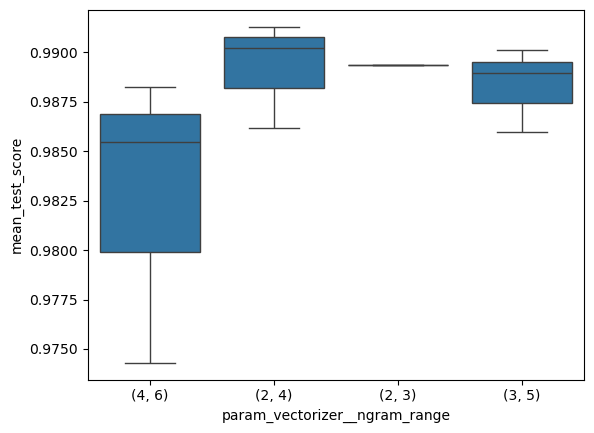

In [10]:
search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True
)

subsample_df = train_df.sample(n=300000, random_state=RANDOM_STATE)
search.fit(subsample_df['url'], subsample_df['is_phishing']) # pass only the url as this is what the vectorizer expects

results = pd.DataFrame(search.cv_results_)
results['param_vectorizer__ngram_range'] = results["param_vectorizer__ngram_range"].astype(str)
sns.boxplot(x="param_vectorizer__ngram_range", y="mean_test_score", data=results)
plt.show()

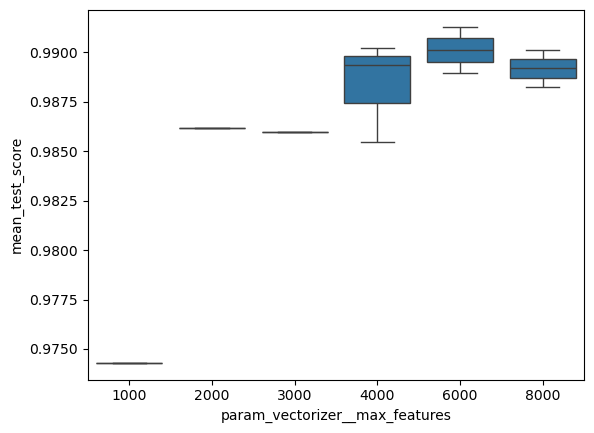

In [11]:
sns.boxplot(x="param_vectorizer__max_features", y="mean_test_score", data=results)
plt.show()

### B. Build best

In [12]:
vectorizer = TfidfVectorizer(
    analyzer="char", # this is because URLs aren't split as words
    ngram_range=(2,4),
    max_features=6000,
)

train_ngrams = vectorizer.fit_transform(train_df['url'])
test_ngrams = vectorizer.transform(test_df['url'])

feature_names = vectorizer.get_feature_names_out()
print(feature_names)
print(train_ngrams.shape, test_ngrams.shape, type(train_ngrams))

['%2' '%20' '%2c' ... 'zx' 'zy' 'zz']
(657593, 6000) (164399, 6000) <class 'scipy.sparse._csr.csr_matrix'>


In [13]:
def print_metrics(ngram_matrix, url_df, i, feature_names):
    url = url_df.iloc[i]['url']
    if url_df.iloc[i]['is_phishing']:
        print("Phishing")
    else:
        print("Legit")

    row = ngram_matrix[i].tocoo()
    sorted_weight_ngram_pairs = sorted(
        zip(row.data, row.col), # zip groups the data and the columns together for sorting
        reverse=True                   # note that data must come first in the zip as is what is being sorted 
    )

    print("URL:", url)
    print("nnz:", row.nnz)
    print("Top 10 ngrams for this URL:")
    print("--------------------------------")

    for weight, ngram_col_index in sorted_weight_ngram_pairs[:10]:
        ngram = feature_names[ngram_col_index]
        print(f"{ngram}, {weight:.4f}")
    print("--------------------------------")
    print()

train_df.reset_index(inplace=True, drop=True) # make sure the matrix and train_df columns match

legit_index = -1
phishing_index = -1

while legit_index == -1 and phishing_index == -1:
    rnumb = random.randint(0, len(train_df))
    if train_df.iloc[rnumb]['is_phishing'] and phishing_index == -1:
        legit_index = rnumb
    elif train_df.iloc[rnumb]['is_phishing'] == False and legit_index == -1:
        phishing_index = rnumb

print_metrics(train_ngrams, train_df, legit_index, feature_names) # legit
print_metrics(train_ngrams, train_df, phishing_index, feature_names) # phishing

Phishing
URL: saramymensinghbd.org/wp-content/Them/pp/Adobe%20PDF.html
nnz: 111
Top 10 ngrams for this URL:
--------------------------------
e%20, 0.1462
0p, 0.1427
e%2, 0.1421
e%, 0.1396
nt/t, 0.1391
t/th, 0.1384
pp/, 0.1378
p/a, 0.1373
sar, 0.1370
nsi, 0.1320
--------------------------------

Legit
URL: en.wikipedia.org/wiki/CFMB
nnz: 61
Top 10 ngrams for this URL:
--------------------------------
wiki, 0.2355
wik, 0.2349
iki, 0.2335
ik, 0.2139
ki, 0.1947
wi, 0.1946
ki/c, 0.1761
i/c, 0.1716
cfm, 0.1673
fm, 0.1433
--------------------------------



### C. Quick check

In [14]:
reg = LogisticRegression(max_iter=1000)
reg.fit(train_ngrams, train_df['is_phishing'])

preds = reg.predict(test_ngrams)
probs = reg.predict_proba(test_ngrams)

accuracy = accuracy_score(test_df['is_phishing'], preds)
auc = roc_auc_score(test_df['is_phishing'], probs[:, 1])
print('Accuracy:', accuracy)
print('AUC:', auc)

Accuracy: 0.960778350233274
AUC: 0.9920264144705883


## 5. Save the files for training

In [15]:
def clean_nans(temp_df):
    for col in temp_df.columns:
        count = temp_df[col].isna().sum()
        if count > 0:
            print(f"{col} has {count} NaNs")
            temp_df[col].fillna(0, inplace=True)
    return temp_df

print("Cleaning training")
train_df = clean_nans(train_df)
print("Cleaning testing")
test_df = clean_nans(test_df)

Cleaning training
digit_letter_ratio has 3 NaNs
Cleaning testing


C:\Users\User\AppData\Local\Temp\ipykernel_19616\1047303556.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp_df[col].fillna(0, inplace=True)


In [16]:
artifact = {
    "train_df" : train_df,
    "test_df" : test_df,
    "train_ngrams": train_ngrams,
    "test_ngrams": test_ngrams,
    "vectorizer": vectorizer,
    "vectorizer_cols": feature_names # needed to store all of the ngram names
}

joblib.dump(artifact, ARTIFACT_PATH)

['C:\\Users\\User\\Documents\\Key Future Docs\\Projects\\Phising URL\\artifacts\\artifact.joblib']